<a href="https://colab.research.google.com/github/fasihahusain/customer-segmentation/blob/main/Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving segmentation data.csv to segmentation data.csv


In [2]:
!ls

 sample_data  'segmentation data.csv'


          ID  Sex  Marital status  Age  Education  Income  Occupation  \
0  100000001    0               0   67          2  124670           1   
1  100000002    1               1   22          1  150773           1   
2  100000003    0               0   49          1   89210           0   
3  100000004    0               0   45          1  171565           1   
4  100000005    0               0   53          1  149031           1   

   Settlement size  
0                2  
1                2  
2                0  
3                1  
4                1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   ID               2000 non-null   int64
 1   Sex              2000 non-null   int64
 2   Marital status   2000 non-null   int64
 3   Age              2000 non-null   int64
 4   Education        2000 non-null   int64
 5   Income          

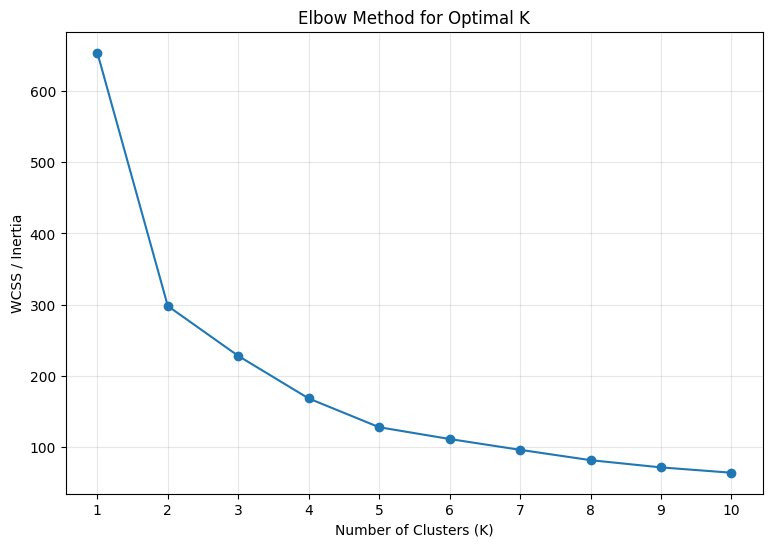


K-MEANS
Cluster sizes: [587 328 402 444 239]
Inertia: 127.4957189353864
Silhouette Score: 0.5206928294821471
Davies-Bouldin Score: 0.8411467522839515


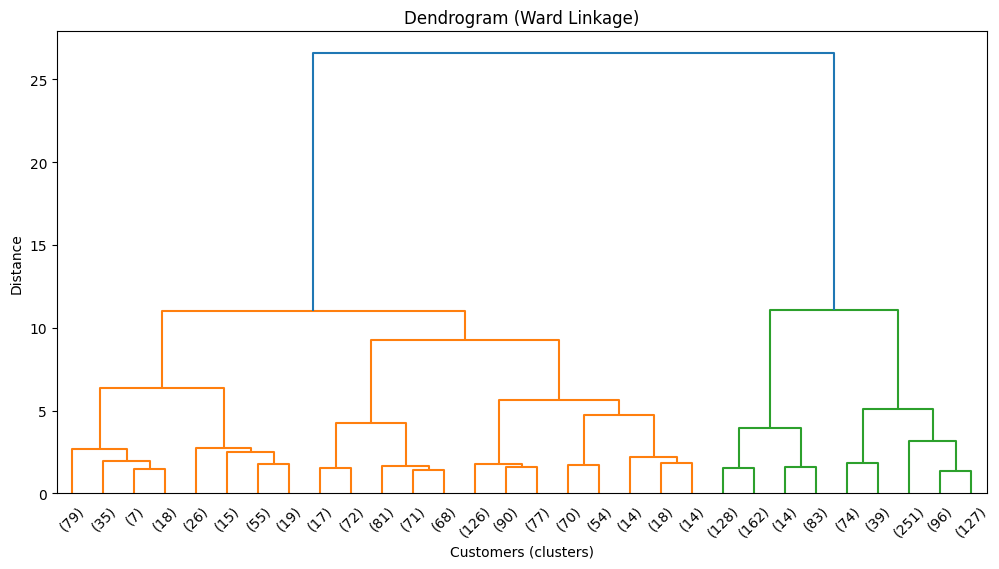


HIERARCHICAL CLUSTERING
Cluster sizes: [254 463 387 587 309]
Silhouette Score: 0.5046082685991176
Davies-Bouldin Score: 0.875743073295628


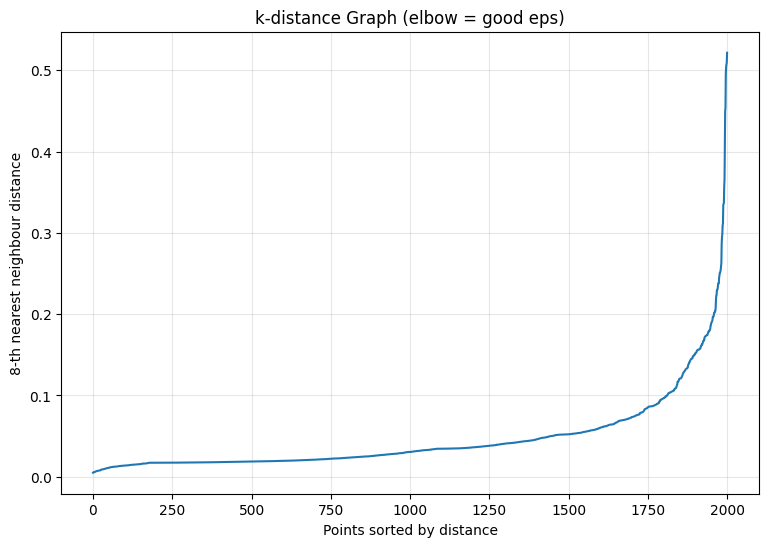


DBSCAN
Clusters found: 10
Noise points: 48
Silhouette Score: 0.5663651473968966
Davies-Bouldin Score: 0.6331681515347152

COMPARISON TABLE:
      Algorithm  Clusters  Noise Points  Silhouette Score  \
0       K-Means         5             0          0.520693   
1  Hierarchical         5             0          0.504608   
2        DBSCAN        10            48          0.566365   

   Davies-Bouldin Score  
0              0.841147  
1              0.875743  
2              0.633168  

Highest Silhouette Score: DBSCAN

Clustered dataset:
          ID  Sex  Marital status  Age  Education  Income  Occupation  \
0  100000001    0               0   67          2  124670           1   
1  100000002    1               1   22          1  150773           1   
2  100000003    0               0   49          1   89210           0   
3  100000004    0               0   45          1  171565           1   
4  100000005    0               0   53          1  149031           1   
5  100000006    0 

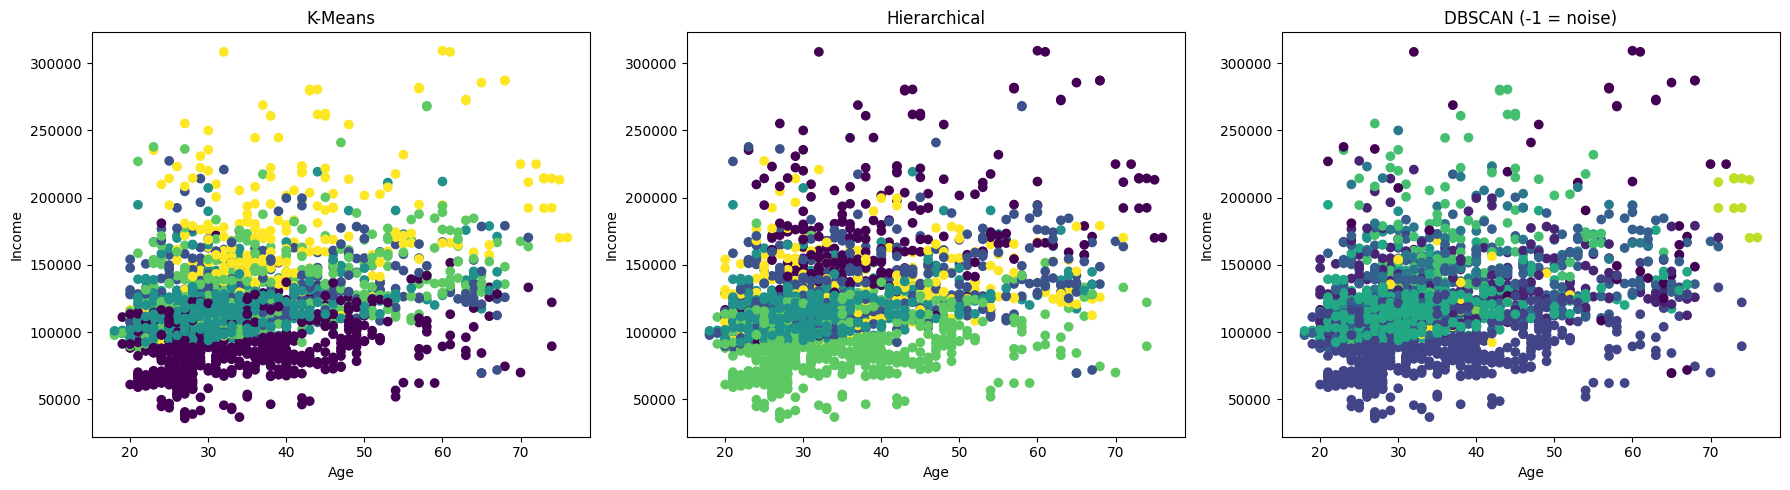


Average feature values in each K-Means cluster:
                      Age         Income  Occupation  Settlement size
KMeans_Cluster                                                       
0               34.872232   88167.074957    0.000000          0.00000
1               36.076220  128616.070122    0.942073          2.00000
2               33.457711  119890.634328    1.037313          0.00000
3               36.614865  129643.817568    0.939189          1.00000
4               41.037657  176614.242678    2.000000          1.58159


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("segmentation data.csv")
print(df.head())
print(df.info())

features = [
    "Age",
    "Income",
    "Occupation",
    "Settlement size"
]
X = df[features].dropna()
print(X.head())

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import KMeans

wcss = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=1
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

print("\nWCSS values:")
print(wcss)

plt.figure(figsize=(9, 6))
plt.plot(k_values, wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=1
)

labels_kmeans = kmeans.fit_predict(X_scaled)

sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
db_kmeans = davies_bouldin_score(X_scaled, labels_kmeans)

print("\nK-MEANS")
print("Cluster sizes:", np.bincount(labels_kmeans))
print("Inertia:", kmeans.inertia_)
print("Silhouette Score:", sil_kmeans)
print("Davies-Bouldin Score:", db_kmeans)

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(
    linked,
    truncate_mode="lastp",
    p=30
)
plt.xlabel("Customers (clusters)")
plt.ylabel("Distance")
plt.title("Dendrogram (Ward Linkage)")
plt.show()

hc = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

labels_hc = hc.fit_predict(X_scaled)

sil_hc = silhouette_score(X_scaled, labels_hc)
db_hc = davies_bouldin_score(X_scaled, labels_hc)

print("\nHIERARCHICAL CLUSTERING")
print("Cluster sizes:", np.bincount(labels_hc))
print("Silhouette Score:", sil_hc)
print("Davies-Bouldin Score:", db_hc)

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

min_samples = 2 * len(features)

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 6))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(str(min_samples) + "-th nearest neighbour distance")
plt.title("k-distance Graph (elbow = good eps)")
plt.grid(True, alpha=0.3)
plt.show()

dbscan = DBSCAN(
    eps=0.15,
    min_samples=min_samples
)

labels_db = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = list(labels_db).count(-1)

print("\nDBSCAN")
print("Clusters found:", n_clusters_db)
print("Noise points:", n_noise)

mask = labels_db != -1

if n_clusters_db > 1:
    sil_db = silhouette_score(X_scaled[mask], labels_db[mask])
    db_db = davies_bouldin_score(X_scaled[mask], labels_db[mask])
else:
    sil_db = np.nan
    db_db = np.nan

print("Silhouette Score:", sil_db)
print("Davies-Bouldin Score:", db_db)

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical", "DBSCAN"],
    "Clusters": [optimal_k, optimal_k, n_clusters_db],
    "Noise Points": [0, 0, n_noise],
    "Silhouette Score": [sil_kmeans, sil_hc, sil_db],
    "Davies-Bouldin Score": [db_kmeans, db_hc, db_db]
})

print("\nCOMPARISON TABLE:")
print(comparison)

best = comparison.loc[comparison["Silhouette Score"].idxmax(), "Algorithm"]
print("\nHighest Silhouette Score:", best)

df_clustered = df.loc[X.index].copy()
df_clustered["KMeans_Cluster"] = labels_kmeans
df_clustered["Hierarchical_Cluster"] = labels_hc
df_clustered["DBSCAN_Cluster"] = labels_db

print("\nClustered dataset:")
print(df_clustered.head(10))

x_col = "Age"
y_col = "Income"

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X[x_col], X[y_col], c=labels_kmeans, cmap="viridis")
axes[0].set_title("K-Means")

axes[1].scatter(X[x_col], X[y_col], c=labels_hc, cmap="viridis")
axes[1].set_title("Hierarchical")

axes[2].scatter(X[x_col], X[y_col], c=labels_db, cmap="viridis")
axes[2].set_title("DBSCAN (-1 = noise)")

for ax in axes:
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

plt.tight_layout()
plt.show()

print("\nAverage feature values in each K-Means cluster:")
print(df_clustered.groupby("KMeans_Cluster")[features].mean())